## Imports, paths, functions

In [1]:
import numpy as np
import pandas as pd
import os, shutil
from tqdm import tqdm
import matplotlib.pyplot as plt
import pickle
import copy
import re
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

from sblearn.models import SymbolicRegressor

In [2]:
%matplotlib inline

In [3]:
meta_input_dir = "/home-local2/sasah14.extra.nobkp/scratch/out/stta/sweep/blockstats/ckpt_sep1"
meta_label_dir = "/home-local2/sasah14.extra.nobkp/scratch/out/stta/sweep/bestmultiruns"
sweep_names = [
    "PACS_resnet18-BN_ERM_0", "VLCS_resnet18-BN_ERM_0", "OfficeHome_resnet18-BN_ERM_0",# "TerraIncognita_resnet18-BN_ERM_0",
    "PACS_resnet50-BN_ERM_0", "VLCS_resnet50-BN_ERM_0", "OfficeHome_resnet50-BN_ERM_0",# "TerraIncognita_resnet50-BN_ERM_0"
]
tta_names = [
    'PseudoLabel', 'SHOT'
]
src_name = 'train_out'
tgt_name = 'test_in'
stats_fname = 'block_stats.csv'
label_fname = 'corr_shap.csv'
sweep_names = sweep_names
sweep_names, tta_names

(['PACS_resnet18-BN_ERM_0',
  'VLCS_resnet18-BN_ERM_0',
  'OfficeHome_resnet18-BN_ERM_0',
  'PACS_resnet50-BN_ERM_0',
  'VLCS_resnet50-BN_ERM_0',
  'OfficeHome_resnet50-BN_ERM_0'],
 ['PseudoLabel', 'SHOT'])

In [4]:
# specifying heldout_dataset creates a train/test split with the specified dataset as the test set
heldout_dataset = None      # None, 'PACS', 'VLCS', 'OfficeHome', '18', '50', 'PseudoLabel', 'SHOT'

# all targets at once or online, online targets increase number of samples, which can improve performance
tgt_online = True          # True, False

# only train on source domain stats
src_only = False            # True, False

# only train on mean and std of source domain stats
mean_std_only = True        # True, False

y_feat = 'shap'             # 'corr', 'shap'
x_feat_str = ''             # '', 'grad', 'out', 'param'

# save random forest meta model
# save_rf_meta_model = False  # True, False

In [5]:
mean_std_str = 'mean|std'
# mean_std_str = 'min|perc_25|median|perc_75|max'
src_str = 'src'

## Dataset preprocessing

Load meta inputs and meta labels

In [6]:
sweep_name = sweep_names[0]
tta_name = tta_names[0]

# Get sweep dir
sweep_dir = os.path.join(meta_input_dir, sweep_name)

# Get runs
runs = [run for run in sorted(os.listdir(sweep_dir))
                                        if os.path.isdir(os.path.join(sweep_dir, run))]

In [7]:
run = runs[0]
run

'075e460d9087c1c387f1d20ef5962584'

In [8]:
x_list, y_list = [], []
info_list = []
x_tr_list, y_tr_list, x_te_list, y_te_list = [], [], [], []

# For different datasets and backbones
for sweep_name in sweep_names:
    dataset, backbone, dg, mark = sweep_name.split('_')
    print('dataset: {}, backbone: {}'.format(dataset, backbone))

    # Get sweep dir
    sweep_dir = os.path.join(meta_input_dir, sweep_name)

    # Get runs
    runs = [run for run in sorted(os.listdir(sweep_dir))
                                        if os.path.isdir(os.path.join(sweep_dir, run))]

    # For different TTAs
    for tta_name in tta_names:
        print('\ttta: {}'.format(tta_name))

        # For different envs per dataset and backbone
        for run in runs:
            ### Read xsrc, xtgt, y_single
            df_xsrc = pd.read_csv(os.path.join(meta_input_dir, sweep_name, run, tta_name, src_name, stats_fname))
            df_xtgt = pd.read_csv(os.path.join(meta_input_dir, sweep_name, run, tta_name, tgt_name, stats_fname))
            if not tgt_online:
                df_xtgt = df_xtgt.mean(axis=0).to_frame().T
            df_y_single = pd.read_csv(os.path.join(meta_label_dir, sweep_name, run, tta_name, label_fname), index_col=0)

            ### meta input processing
            # Add prefix 'src_' to all xsrc columns
            df_xsrc = df_xsrc.add_prefix('xsrc_')

            # Add prefix 'tgt_' to all xtgt columns
            df_xtgt = df_xtgt.add_prefix('xtgt_')

            # take mean
            df_xsrc_mean = df_xsrc.mean().to_frame().T

            # repeat the row to match xtgt
            df_xsrc_mean = pd.concat([df_xsrc_mean]*df_xtgt.shape[0], ignore_index=True)

            ### meta label processing
            # Remove first 5 characters from all indices in df_y_single
            df_y_single.index = df_y_single.index.str[5:]

            # Remove first and last rows from df_y_single
            df_ycorr_single = df_y_single[['corr']][1:-1]
            df_yshap_single = df_y_single[['shap']][1:-1]

            # Add prefix to column names
            df_ycorr_single = df_ycorr_single.T.add_prefix('ycorr_')
            df_yshap_single = df_yshap_single.T.add_prefix('yshap_')

            # repeat the row to match xtgt
            df_ycorr = pd.concat([df_ycorr_single]*df_xtgt.shape[0], ignore_index=True)
            df_yshap = pd.concat([df_yshap_single]*df_xtgt.shape[0], ignore_index=True)

            ### merge with xtgt
            df_xone = pd.concat([df_xtgt, df_xsrc_mean], axis=1)
            df_yone = pd.concat([df_ycorr, df_yshap], axis=1)
            print('\t\tdf_xone.shape: ', df_xone.shape)
            x_list.append(df_xone)
            y_list.append(df_yone)

            df_info = pd.DataFrame()
            df_info['dataset'] = [dataset for _ in range(df_xone.shape[0])]
            df_info['backbone'] = [backbone for _ in range(df_xone.shape[0])]
            df_info['dg'] = [dg for _ in range(df_xone.shape[0])]
            df_info['mark'] = [mark for _ in range(df_xone.shape[0])]
            df_info['tta_name'] = [tta_name for _ in range(df_xone.shape[0])]
            df_info['run'] = [run for _ in range(df_xone.shape[0])]
            info_list.append(df_info)

            if heldout_dataset is not None:
                if heldout_dataset in dataset or heldout_dataset in backbone or heldout_dataset in tta_name:
                    x_te_list.append(df_xone)
                    y_te_list.append(df_yone)
                else:
                    x_tr_list.append(df_xone)
                    y_tr_list.append(df_yone)
df_x = pd.concat(x_list, ignore_index=True)
df_y = pd.concat(y_list, ignore_index=True)
df_info = pd.concat(info_list, ignore_index=True)
if heldout_dataset is not None:
    df_x_tr = pd.concat(x_tr_list, ignore_index=True)
    df_y_tr = pd.concat(y_tr_list, ignore_index=True)
    df_x_te = pd.concat(x_te_list, ignore_index=True)
    df_y_te = pd.concat(y_te_list, ignore_index=True)    
df_x.shape, df_y.shape

dataset: PACS, backbone: resnet18-BN
	tta: PseudoLabel
		df_xone.shape:  (59, 240)
		df_xone.shape:  (42, 240)
		df_xone.shape:  (52, 240)
		df_xone.shape:  (99, 240)
	tta: SHOT
		df_xone.shape:  (59, 240)
		df_xone.shape:  (42, 240)
		df_xone.shape:  (52, 240)
		df_xone.shape:  (99, 240)
dataset: VLCS, backbone: resnet18-BN
	tta: PseudoLabel
		df_xone.shape:  (67, 240)
		df_xone.shape:  (83, 240)
		df_xone.shape:  (85, 240)
		df_xone.shape:  (36, 240)
	tta: SHOT
		df_xone.shape:  (67, 240)
		df_xone.shape:  (83, 240)
		df_xone.shape:  (85, 240)
		df_xone.shape:  (36, 240)
dataset: OfficeHome, backbone: resnet18-BN
	tta: PseudoLabel
		df_xone.shape:  (61, 240)
		df_xone.shape:  (111, 240)
		df_xone.shape:  (110, 240)
		df_xone.shape:  (109, 240)
	tta: SHOT
		df_xone.shape:  (61, 240)
		df_xone.shape:  (111, 240)
		df_xone.shape:  (110, 240)
		df_xone.shape:  (109, 240)
dataset: PACS, backbone: resnet50-BN
	tta: PseudoLabel
		df_xone.shape:  (59, 240)
		df_xone.shape:  (99, 240)
		df_xo

((3656, 240), (3656, 8))

In [9]:
df_x.sample()

,xtgt_1_out_mean,xtgt_1_out_std,xtgt_1_out_max,xtgt_1_out_min,xtgt_1_out_median,xtgt_1_out_perc_25,xtgt_1_out_perc_75,xtgt_1_out_perc_90,xtgt_1_out_perc_95,xtgt_1_out_perc_99,...,xsrc_4_grad_mean,xsrc_4_grad_std,xsrc_4_grad_max,xsrc_4_grad_min,xsrc_4_grad_median,xsrc_4_grad_perc_25,xsrc_4_grad_perc_75,xsrc_4_grad_perc_90,xsrc_4_grad_perc_95,xsrc_4_grad_perc_99
2930,0.179565,0.187527,3.613125,0.0,0.14699,0.012615,0.269109,0.408791,0.515141,0.824219,...,-0.000003,0.001751,0.191685,-0.220636,0.000012,-0.000438,0.000465,0.00134,0.002193,0.004887


In [10]:
df_y.sample()

,ycorr_1,ycorr_2,ycorr_3,ycorr_4,yshap_1,yshap_2,yshap_3,yshap_4
3625,0.02544,0.104585,0.568153,0.206344,0.000146,0.002549,0.007441,0.003235


In [11]:
df_xtgt.shape

(61, 120)

In [12]:
df_x.shape, df_info.shape

((3656, 240), (3656, 6))

In [13]:
df_info

,dataset,backbone,dg,mark,tta_name,run
0,PACS,resnet18-BN,ERM,0,PseudoLabel,075e460d9087c1c387f1d20ef5962584
1,PACS,resnet18-BN,ERM,0,PseudoLabel,075e460d9087c1c387f1d20ef5962584
2,PACS,resnet18-BN,ERM,0,PseudoLabel,075e460d9087c1c387f1d20ef5962584
3,PACS,resnet18-BN,ERM,0,PseudoLabel,075e460d9087c1c387f1d20ef5962584
4,PACS,resnet18-BN,ERM,0,PseudoLabel,075e460d9087c1c387f1d20ef5962584
...,...,...,...,...,...,...
3651,OfficeHome,resnet50-BN,ERM,0,SHOT,fd6bc3e808e9b46f91e5ed6e2c9bcfb7
3652,OfficeHome,resnet50-BN,ERM,0,SHOT,fd6bc3e808e9b46f91e5ed6e2c9bcfb7
3653,OfficeHome,resnet50-BN,ERM,0,SHOT,fd6bc3e808e9b46f91e5ed6e2c9bcfb7
3654,OfficeHome,resnet50-BN,ERM,0,SHOT,fd6bc3e808e9b46f91e5ed6e2c9bcfb7


Select only some feats to train -- skipped for now!

In [14]:
if heldout_dataset is None:
    # Filter columns of a dataframe which do not contain the string "mean" or "std" in their name
    if mean_std_only:
        df_x = df_x[df_x.columns[df_x.columns.str.contains(mean_std_str)]]
    if src_only:
        df_x = df_x[df_x.columns[df_x.columns.str.contains(src_str)]]
    if x_feat_str != '':
        df_x = df_x[df_x.columns[df_x.columns.str.contains(x_feat_str)]]

    # Filter columns of a dataframe which do not contain the string y_feat string ("shap") in their name
    df_y = df_y[df_y.columns[df_y.columns.str.contains(y_feat)]]
else:
    # Filter columns of a dataframe which do not contain the string "mean" or "std" in their name
    if mean_std_only:
        df_x_tr = df_x_tr[df_x_tr.columns[df_x_tr.columns.str.contains(mean_std_str)]]
        df_x_te = df_x_te[df_x_te.columns[df_x_te.columns.str.contains(mean_std_str)]]

    if src_only:
        df_x_tr = df_x_tr[df_x_tr.columns[df_x_tr.columns.str.contains(src_str)]]
        df_x_te = df_x_te[df_x_te.columns[df_x_te.columns.str.contains(src_str)]]

    if x_feat_str != '':
        df_x_tr = df_x_tr[df_x_tr.columns[df_x_tr.columns.str.contains(x_feat_str)]]
        df_x_te = df_x_te[df_x_te.columns[df_x_te.columns.str.contains(x_feat_str)]]

    # Filter columns of a dataframe which do not contain the string "shap" in their name
    df_y_tr = df_y_tr[df_y_tr.columns[df_y_tr.columns.str.contains(y_feat)]]
    df_y_te = df_y_te[df_y_te.columns[df_y_te.columns.str.contains(y_feat)]]

In [15]:
df_x.columns, df_y.columns

(Index(['xtgt_1_out_mean', 'xtgt_1_out_std', 'xtgt_1_params_mean',
        'xtgt_1_params_std', 'xtgt_1_grad_mean', 'xtgt_1_grad_std',
        'xtgt_2_out_mean', 'xtgt_2_out_std', 'xtgt_2_params_mean',
        'xtgt_2_params_std', 'xtgt_2_grad_mean', 'xtgt_2_grad_std',
        'xtgt_3_out_mean', 'xtgt_3_out_std', 'xtgt_3_params_mean',
        'xtgt_3_params_std', 'xtgt_3_grad_mean', 'xtgt_3_grad_std',
        'xtgt_4_out_mean', 'xtgt_4_out_std', 'xtgt_4_params_mean',
        'xtgt_4_params_std', 'xtgt_4_grad_mean', 'xtgt_4_grad_std',
        'xsrc_1_out_mean', 'xsrc_1_out_std', 'xsrc_1_params_mean',
        'xsrc_1_params_std', 'xsrc_1_grad_mean', 'xsrc_1_grad_std',
        'xsrc_2_out_mean', 'xsrc_2_out_std', 'xsrc_2_params_mean',
        'xsrc_2_params_std', 'xsrc_2_grad_mean', 'xsrc_2_grad_std',
        'xsrc_3_out_mean', 'xsrc_3_out_std', 'xsrc_3_params_mean',
        'xsrc_3_params_std', 'xsrc_3_grad_mean', 'xsrc_3_grad_std',
        'xsrc_4_out_mean', 'xsrc_4_out_std', 'xsrc_4_pa

In [16]:
new_col_names = list(set(["_".join([col.split('_')[0]] + list(np.array(col.split('_'))[2:])) for col in df_x.columns]))
new_col_names

# Concatenate all features for different blocks
block_list = [1, 2, 3, 4]

new_col_name = new_col_names[0]
new_col_name

'xsrc_grad_mean'

In [17]:
old_col_list = ["_".join([new_col_name.split('_')[0]] + [str(block_idx)] + list(np.array(new_col_name.split('_'))[1:])) for block_idx in block_list]
df_x[old_col_list]

,xsrc_1_grad_mean,xsrc_2_grad_mean,xsrc_3_grad_mean,xsrc_4_grad_mean
0,-0.000063,0.000007,-1.704734e-07,-0.000002
1,-0.000063,0.000007,-1.704734e-07,-0.000002
2,-0.000063,0.000007,-1.704734e-07,-0.000002
3,-0.000063,0.000007,-1.704734e-07,-0.000002
4,-0.000063,0.000007,-1.704734e-07,-0.000002
...,...,...,...,...
3651,0.000031,0.000008,1.649156e-05,0.000007
3652,0.000031,0.000008,1.649156e-05,0.000007
3653,0.000031,0.000008,1.649156e-05,0.000007
3654,0.000031,0.000008,1.649156e-05,0.000007


Meta dataset split 

In [18]:
# Split df_x and df_y into train, valid and test splits
if heldout_dataset is None:
    df_x_train, df_x_nottrain, df_y_train, df_y_nottrain = train_test_split(df_x, df_y, test_size=0.2, random_state=1)
    df_x_valid, df_x_test, df_y_valid, df_y_test = train_test_split(df_x_nottrain, df_y_nottrain, test_size=0.5, random_state=1) # 0.5 x 0.2 = 0.1
else:
    df_x_train, df_x_nottrain, df_y_train, df_y_nottrain = df_x_tr, df_x_te, df_y_tr, df_y_te
    df_x_valid, df_x_test, df_y_valid, df_y_test = train_test_split(df_x_te, df_y_te, test_size=0.5, random_state=1)

In [19]:
(df_x_train.shape, df_x_valid.shape, df_x_test.shape), (df_y_train.shape, df_y_valid.shape, df_y_test.shape)

(((2924, 48), (366, 48), (366, 48)), ((2924, 4), (366, 4), (366, 4)))

Normalize the dataset

In [20]:
# Normalize df_x_train, df_x_valid and df_x_test for each column
df_x_train_norm = (df_x_train - df_x_train.mean()) / df_x_train.std()
df_x_valid_norm = (df_x_valid - df_x_train.mean()) / df_x_train.std()
df_x_test_norm = (df_x_test - df_x_train.mean()) / df_x_train.std()

## Automatically determine the metric

Use meta learning to extract most imp feature

In [21]:
feat_models = {
    # 'lr': LinearRegression(),
    'lasso': Lasso(alpha=1e-5),
    'ridge': Ridge(alpha=1e-4),
    # 'dt': DecisionTreeRegressor(),
    # 'rf': RandomForestRegressor(),
    # 'gb': GradientBoostingRegressor(),
    # 'sblearn': SymbolicRegressor(n_iter=20, max_depth='auto', simpler_is_better=True, verbose=1, random_state=None),
    'sblearn': SymbolicRegressor(n_iter=1, max_depth=2, simpler_is_better=True, verbose=1, random_state=None),
}

plot_feat = False   # True, False
plot_err = True    # True, False

lasso:   0%|          | 0/4 [00:00<?, ?it/s]/home-local2/sasah14.extra.nobkp/envs/ttdg/lib/python3.8/site-packages/sklearn/linear_model/_coordinate_descent.py:648: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.726e-05, tolerance: 3.045e-05
  model = cd_fast.enet_coordinate_descent(
/home-local2/sasah14.extra.nobkp/envs/ttdg/lib/python3.8/site-packages/sklearn/linear_model/_coordinate_descent.py:648: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.098e-03, tolerance: 1.909e-04
  model = cd_fast.enet_coordinate_descent(
sblearn:   0%|          | 0/4 [00:00<?, ?it/s]/home-local2/sasah14.extra.nobkp/envs/ttdg/lib/python3.8/site-packages/sklearn/utils/validation.py:1111: DataConversionWarning: A column-vector y was 

BEST SOLUTION:
y0 = 0.03810645267367363*x5


/home-local2/sasah14.extra.nobkp/envs/ttdg/lib/python3.8/site-packages/sklearn/utils/validation.py:1111: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
sblearn:  50%|█████     | 2/4 [00:10<00:10,  5.36s/it]

BEST SOLUTION:
y0 = -x11 + x5


/home-local2/sasah14.extra.nobkp/envs/ttdg/lib/python3.8/site-packages/sklearn/utils/validation.py:1111: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
sblearn:  75%|███████▌  | 3/4 [00:15<00:05,  5.08s/it]

BEST SOLUTION:
y0 = x5 - 0.009767381474375725


/home-local2/sasah14.extra.nobkp/envs/ttdg/lib/python3.8/site-packages/sklearn/utils/validation.py:1111: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
sblearn: 100%|██████████| 4/4 [00:20<00:00,  5.13s/it]

BEST SOLUTION:
y0 = x10/x11


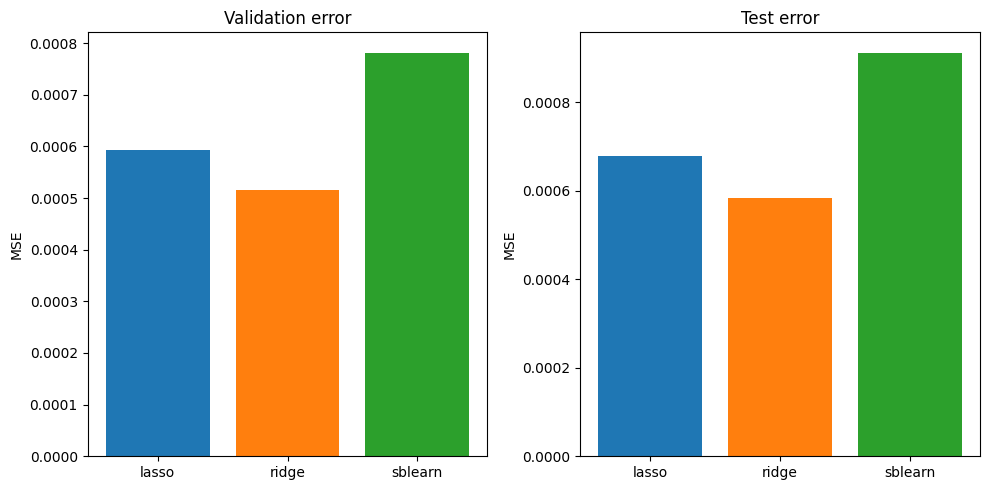

In [22]:
block_list = [1, 2, 3, 4]

trained_feat_models, err_valid_dict, err_test_dict = {}, {}, {}
block_cols = [df_x_train.columns[df_x_train.columns.str.contains(str(block_idx))] for block_idx in block_list]

for feat_model_name, feat_model in feat_models.items():
    trained_feat_models[feat_model_name] = []
    err_valid_dict[feat_model_name] = []
    err_test_dict[feat_model_name] = []
    for block_idx in tqdm(block_list, desc=feat_model_name):
        # Get the block columns
        df_x_train_block = df_x_train[df_x_train.columns[df_x_train.columns.str.contains(str(block_idx))]]
        df_x_valid_block = df_x_valid[df_x_valid.columns[df_x_valid.columns.str.contains(str(block_idx))]]
        df_x_test_block = df_x_test[df_x_test.columns[df_x_test.columns.str.contains(str(block_idx))]]

        df_y_train_block = df_y_train[df_y_train.columns[df_y_train.columns.str.contains(y_feat + '_' + str(block_idx))]]
        df_y_valid_block = df_y_valid[df_y_valid.columns[df_y_valid.columns.str.contains(y_feat + '_' + str(block_idx))]]
        df_y_test_block = df_y_test[df_y_test.columns[df_y_test.columns.str.contains(y_feat + '_' + str(block_idx))]]

        # Train the model
        feat_model = copy.deepcopy(feat_model)
        feat_model.fit(df_x_train_block, df_y_train_block)

        # Evaluate the model
        err_valid_dict[feat_model_name].append(mean_squared_error(df_y_valid_block, feat_model.predict(df_x_valid_block)))
        err_test_dict[feat_model_name].append(mean_squared_error(df_y_test_block, feat_model.predict(df_x_test_block)))

        # Save the trained model
        trained_feat_models[feat_model_name].append(feat_model)

    # Plot the imp coeffs for each block as a subfigure in a single figure
    if plot_feat:
        fig, axs = plt.subplots(2, 2, figsize=(10, 10))
        for block_idx in range(4):
            # Get the imp coefficients and features
            if feat_model_name in ['lr', 'lasso', 'ridge']:
                coeff = trained_feat_models[feat_model_name][block_idx].coef_
            elif feat_model_name in ['dt', 'rf', 'gb']:
                coeff = trained_feat_models[feat_model_name][block_idx].feature_importances_
            elif feat_model_name in ['sblearn']:
                continue
            else:
                raise ValueError('Invalid feat_model_name')
            
            # Get the imp coefficients and features
            imp_flag = np.abs(coeff) > np.abs(coeff).mean()# + np.abs(coeff).std()
            imp_coeff = np.abs(coeff[imp_flag])
            imp_flag = np.squeeze(imp_flag)
            imp_feats = block_cols[block_idx][imp_flag]

            # Plot the impcoefficients sorted by their magnitude
            sorted_order = np.argsort(imp_coeff)
            imp_coeff = imp_coeff[sorted_order]
            imp_feats = imp_feats[sorted_order]
            axs[block_idx//2, block_idx%2].barh(imp_feats, imp_coeff)
            axs[block_idx//2, block_idx%2].set_title('Block ' + str(block_idx+1))
            axs[block_idx//2, block_idx%2].set_xlabel('Feature')
            axs[block_idx//2, block_idx%2].set_ylabel('Coefficient')
            # axs[block_idx//2, block_idx%2].tick_params(axis='x', rotation=90)
        fig.suptitle('Feature coefficients for ' + feat_model_name + ' regression')
        plt.tight_layout()
        plt.show()

# Plot the validation and test errors averaged across blocks for each feat_model as bar plot
if plot_err:
    fig, axs = plt.subplots(1, 2, figsize=(10, 5))
    for feat_model_name, feat_model in feat_models.items():
        axs[0].bar(feat_model_name, np.mean(err_valid_dict[feat_model_name]))
        axs[1].bar(feat_model_name, np.mean(err_test_dict[feat_model_name]))
    axs[0].set_title('Validation error')
    axs[1].set_title('Test error')
    axs[0].set_ylabel('MSE')
    axs[1].set_ylabel('MSE')
    plt.tight_layout()
    plt.show()
else:
    print('Validation error: ', err_valid_dict)
    print('Test error: ', err_test_dict)

Block: 1, Formula: y0 = 0.03810645267367363*x5, Extracted columns: ['xtgt_1_grad_std']
y0_tree:                               
(*)                           
 |                            
 | ─────── 0.03810645267367363
 |                            
 | ─────── x5                 
                              
Block: 2, Formula: y0 = -x11 + x5, Extracted columns: ['xsrc_2_grad_std', 'xtgt_2_grad_std']
y0_tree:               
(-)           
 |            
 | ─────── x5 
 |            
 | ─────── x11
              
Block: 3, Formula: y0 = x5 - 0.009767381474375725, Extracted columns: ['xtgt_3_grad_std']
y0_tree:                                
(-)                            
 |                             
 | ─────── x5                  
 |                             
 | ─────── 0.009767381474375725
                               
Block: 4, Formula: y0 = x10/x11, Extracted columns: ['xsrc_4_grad_mean', 'xsrc_4_grad_std']
y0_tree:               
(/)           
 |            
 | ─────── 

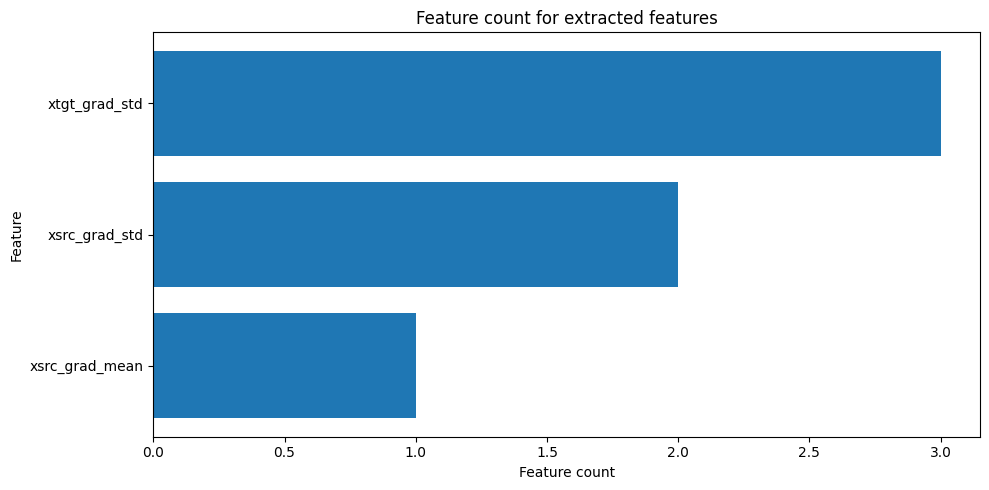

In [23]:
if 'sblearn' in feat_models:
    extracted_col_list = []
    for block_idx in range(4):
        trained_feat_model = trained_feat_models['sblearn'][block_idx]
        formula = trained_feat_model.formulas[0]
        tree = trained_feat_model.trees[0]
        extracted_idxs = [int(col) for col in re.findall(r'x(\d+)', formula)]
        extracted_cols = list(block_cols[block_idx][extracted_idxs])
        extracted_col_list += extracted_cols

        print('Block: {}, Formula: {}, Extracted columns: {}'.format(block_idx+1, formula, extracted_cols))
        print(tree)

    # Plot the feature count for extracted features
    feat_count = dict(Counter(["_".join([col.split('_')[0]] + list(np.array(col.split('_'))[2:])) for col in extracted_col_list]))
    feat_count = {k: v for k, v in sorted(feat_count.items(), key=lambda item: item[1], reverse=False)}

    plt.figure(figsize=(10, 5))
    plt.barh(list(feat_count.keys()), list(feat_count.values()))
    plt.xlabel('Feature count')
    plt.ylabel('Feature')
    plt.title('Feature count for extracted features')
    plt.tight_layout()
    plt.show()

How much do the extracted features correlate with the target?

In [24]:
df_x_train.columns

Index(['xtgt_1_out_mean', 'xtgt_1_out_std', 'xtgt_1_params_mean',
       'xtgt_1_params_std', 'xtgt_1_grad_mean', 'xtgt_1_grad_std',
       'xtgt_2_out_mean', 'xtgt_2_out_std', 'xtgt_2_params_mean',
       'xtgt_2_params_std', 'xtgt_2_grad_mean', 'xtgt_2_grad_std',
       'xtgt_3_out_mean', 'xtgt_3_out_std', 'xtgt_3_params_mean',
       'xtgt_3_params_std', 'xtgt_3_grad_mean', 'xtgt_3_grad_std',
       'xtgt_4_out_mean', 'xtgt_4_out_std', 'xtgt_4_params_mean',
       'xtgt_4_params_std', 'xtgt_4_grad_mean', 'xtgt_4_grad_std',
       'xsrc_1_out_mean', 'xsrc_1_out_std', 'xsrc_1_params_mean',
       'xsrc_1_params_std', 'xsrc_1_grad_mean', 'xsrc_1_grad_std',
       'xsrc_2_out_mean', 'xsrc_2_out_std', 'xsrc_2_params_mean',
       'xsrc_2_params_std', 'xsrc_2_grad_mean', 'xsrc_2_grad_std',
       'xsrc_3_out_mean', 'xsrc_3_out_std', 'xsrc_3_params_mean',
       'xsrc_3_params_std', 'xsrc_3_grad_mean', 'xsrc_3_grad_std',
       'xsrc_4_out_mean', 'xsrc_4_out_std', 'xsrc_4_params_mean',
   

In [25]:
df_y_train.columns

Index(['yshap_1', 'yshap_2', 'yshap_3', 'yshap_4'], dtype='object')

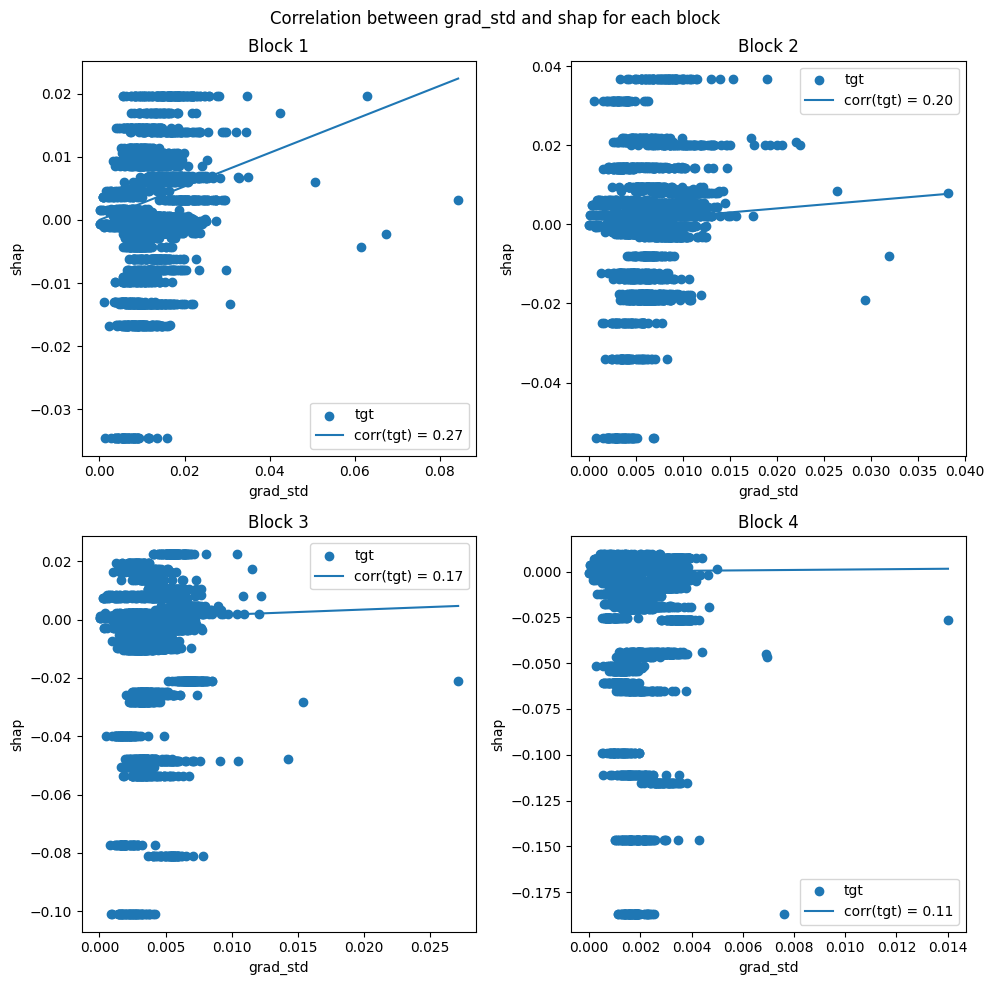

In [26]:
# Plot the correlation line between x_train and y_train for grad_std feature for each block as a subfigure in a single figure separately for src and tgt
block_list = [1, 2, 3, 4]
feat_str = 'grad_std'

fig, axs = plt.subplots(2, 2, figsize=(10, 10))
for block_idx in range(4):
    # Get the block columns
    df_x_train_block = df_x_train[df_x_train.columns[df_x_train.columns.str.contains(str(block_idx+1))]]
    df_y_train_block = df_y_train[df_y_train.columns[df_y_train.columns.str.contains(y_feat + '_' + str(block_idx+1))]]

    # Get the block columns for feat_str
    df_x_train_block_feat = df_x_train_block[df_x_train_block.columns[df_x_train_block.columns.str.contains(feat_str)]]

    # Get the block columns for src and tgt
    df_x_train_block_src = df_x_train_block_feat[df_x_train_block_feat.columns[df_x_train_block_feat.columns.str.contains(src_str)]]
    df_x_train_block_tgt = df_x_train_block_feat[df_x_train_block_feat.columns[df_x_train_block_feat.columns.str.contains('tgt')]]
    # df_x_train_block_tgt = pd.DataFrame(df_x_train_block_tgt.values - df_x_train_block_src.values)

    # Plot the correlation line between x_train and y_train for feat_str feature
    # axs[block_idx//2, block_idx%2].scatter(df_x_train_block_src, df_y_train_block, label='src')
    axs[block_idx//2, block_idx%2].scatter(df_x_train_block_tgt, df_y_train_block, label='tgt')
    axs[block_idx//2, block_idx%2].set_title('Block ' + str(block_idx+1))
    axs[block_idx//2, block_idx%2].set_xlabel(feat_str)
    axs[block_idx//2, block_idx%2].set_ylabel(y_feat)
    # axs[block_idx//2, block_idx%2].tick_params(axis='x', rotation=90)

    # Compute the correlation between x_train and y_train for feat_str feature
    # corr_src = np.corrcoef(df_x_train_block_src, df_y_train_block)[0,1]
    corr_tgt = pd.merge(right=df_y_train_block, left=df_x_train_block_tgt, how='inner', left_index=True, right_index=True).corr().values[0,1]

    # Get the xrange and plot correlation line
    # x_range = np.linspace(df_x_train_block_src.min(), df_x_train_block_src.max(), 100)
    x_range = np.linspace(df_x_train_block_tgt.min(), df_x_train_block_tgt.max(), 100)
    # y_range = x_range * corr_src
    y_range = x_range * corr_tgt
    # axs[block_idx//2, block_idx%2].plot(x_range, y_range, label='src')
    axs[block_idx//2, block_idx%2].plot(x_range, y_range, label='corr(tgt) = {:.2f}'.format(corr_tgt))
    axs[block_idx//2, block_idx%2].legend()

fig.suptitle('Correlation between ' + feat_str + ' and ' + y_feat + ' for each block')
plt.tight_layout()
plt.show()

Use symbolic regression to propose the metric

In [27]:
# block_list = [1, 2, 3, 4]

# symb_model_list = []

# for block_idx in tqdm(block_list):
#     # Define the symbolic regressor model
#     symb_model = SymbolicRegressor(n_iter=20, max_depth='auto', simpler_is_better=True, verbose=1, random_state=42)

#     # Define the column name of the target variable
#     ycol_name = 'yshap_' + str(block_idx)

#     # Fit the model on the training data
#     symb_model.fit(df_x_train, df_y_train[ycol_name].values)

#     # Evaluate the model on the validation data
#     y_valid_pred = symb_model.predict(df_x_valid)
#     mse_valid = mean_squared_error(df_y_valid[ycol_name].values, y_valid_pred)

#     # Evaluate the model on the test data
#     y_test_pred = symb_model.predict(df_x_test)
#     mse_test = mean_squared_error(df_y_test[ycol_name].values, y_test_pred)

#     print('block_idx: {}, formula:{}'.format(block_idx, symb_model.formulas))
#     print('mse_valid: {}, mse_test: {}\n'.format(mse_valid, mse_test))

#     # Save the model
#     symb_model_list.append(symb_model)

Evaluate (regression loss and classification error) the proposed metric

## Manually determine the metrics

Manually extract most important features

How much do the extracted features correlate with the target?

Propose a metric composed of those features

Evaluate (regression loss and classification error) the proposed metric